# Day 4: Probability, Correlation, Data Splitting and Task 1
System 7 Internship | Week 2 | Aayla Zahid Butt

## Probability
- Probability = favourable outcomes / total outcomes. It is always between 0 and 1.
- Two heads in two coin tosses: 0.5 x 0.5 = 0.25 (independent events are multiplied).
- An even number on a die: 3 / 6 = 0.5.
- Conditional probability: P(A | B) = P(A and B) / P(B).

## Correlation
Correlation (r) shows how strongly two numeric columns move together. It goes from -1 (opposite directions) to +1 (same direction). Zero means no linear relationship. Correlation does not mean one thing causes the other.

## Task 1: Explore and prepare a dataset (Pandas and NumPy)
The dataset is a house-price table with 500 rows. It is created with NumPy below, and a few values are left missing on purpose so that cleaning can be practised.

In [1]:
import numpy as np
import pandas as pd

# create the house-price dataset (500 houses)
rng = np.random.default_rng(42)
n = 500
area = rng.normal(1800, 500, n).clip(500, 4000).round(0)
bedrooms = np.clip((area / 700 + rng.normal(0, 0.7, n)).round(), 1, 6).astype(int)
bathrooms = np.clip((bedrooms * 0.7 + rng.normal(0, 0.6, n)).round(), 1, 5).astype(int)
age = rng.integers(0, 50, n)
dist = rng.uniform(1, 25, n).round(1)
price = (35000 + 120 * area + 8000 * bedrooms + 12000 * bathrooms
         - 900 * age - 2500 * dist + rng.normal(0, 25000, n)).round(0)

df = pd.DataFrame(dict(area_sqft=area, bedrooms=bedrooms, bathrooms=bathrooms,
                       house_age=age, dist_city_km=dist, price=price))

# make a few values missing on purpose to practise cleaning
df.loc[rng.choice(n, 12, replace=False), 'house_age'] = np.nan
df.loc[rng.choice(n, 8, replace=False), 'dist_city_km'] = np.nan
df.to_csv('house_prices.csv', index=False)

## Explore

In [2]:
df = pd.read_csv('house_prices.csv')
print(df.shape)
df.head()

(500, 6)


,area_sqft,bedrooms,bathrooms,house_age,dist_city_km,price
0,1952.0,4,3,21.0,19.4,300574.0
1,1280.0,2,1,41.0,8.4,138550.0
2,2175.0,3,2,13.0,6.2,281958.0
3,2270.0,2,2,12.0,17.5,316415.0
4,824.0,1,1,16.0,22.8,94787.0


In [3]:
print(df.isna().sum())

area_sqft        0
bedrooms         0
bathrooms        0
house_age       12
dist_city_km     8
price            0
dtype: int64


In [4]:
df.describe().round(2)

,area_sqft,bedrooms,bathrooms,house_age,dist_city_km,price
count,500.00,500.00,500.00,488.00,492.00,500.00
mean,1793.43,2.54,1.86,24.51,12.79,239614.88
std,479.98,0.98,0.83,14.63,6.94,77996.72
min,517.00,1.00,1.00,0.00,1.00,8865.00
25%,1466.25,2.00,1.00,11.00,7.10,182210.50
50%,1801.50,3.00,2.00,23.00,12.40,238508.50
75%,2093.50,3.00,2.00,38.00,19.00,292309.25
max,3257.00,5.00,5.00,49.00,25.00,472203.00


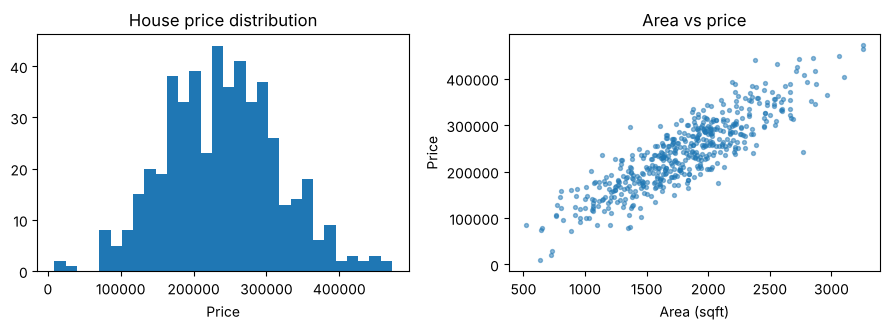

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].hist(df.price, bins=30)
ax[0].set_title('House price distribution')
ax[0].set_xlabel('Price')
ax[1].scatter(df.area_sqft, df.price, s=8, alpha=0.5)
ax[1].set_title('Area vs price')
ax[1].set_xlabel('Area (sqft)')
ax[1].set_ylabel('Price')
plt.tight_layout()
plt.show()

## Clean: fill missing values with the median

In [6]:
df['house_age'] = df['house_age'].fillna(df['house_age'].median())
df['dist_city_km'] = df['dist_city_km'].fillna(df['dist_city_km'].median())
print(df.isna().sum())
df.to_csv('house_prices_clean.csv', index=False)

area_sqft       0
bedrooms        0
bathrooms       0
house_age       0
dist_city_km    0
price           0
dtype: int64


## Correlation with price

In [7]:
df.corr()['price'].drop('price').sort_values(ascending=False).round(3)

area_sqft       0.875
bedrooms        0.674
bathrooms       0.541
house_age      -0.153
dist_city_km   -0.296
Name: price, dtype: float64

Area has the strongest relation with price. Bedrooms and bathrooms are also positive. House age and distance from the city are slightly negative, so older and farther houses are a little cheaper.

## Probabilities from the data

In [8]:
p_big = (df.area_sqft > 2000).mean()
p_exp = (df.price > df.price.median()).mean()
p_both = ((df.area_sqft > 2000) & (df.price > df.price.median())).mean()

print('P(area > 2000 sqft)               :', round(p_big, 2))
print('P(price above the median)         :', round(p_exp, 2))
print('P(price above median | area>2000) :', round(p_both / p_big, 3))

P(area > 2000 sqft)               : 0.32
P(price above the median)         : 0.5
P(price above median | area>2000) : 0.938


## Train, validation and test split (70 / 15 / 15)
- Training set: the model learns from this.
- Validation set: used to compare models and settings.
- Test set: kept aside for the final check, used only once.

In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='price')
y = df['price']

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42)

print('train      :', len(X_tr))
print('validation :', len(X_val))
print('test       :', len(X_te))

train      : 350
validation : 75
test       : 75
